# 27. Molecular Property Prediction
@Shengli (Bruce) Jiang, University of South Carolina

## Setup

Keep the `data` folder beside this notebook.
Install packages with `%pip install rdkit numpy pandas matplotlib scikit-learn pillow`.

The CSV files contain 1106 ESOL molecules and 1915 BBBP molecules from
[MoleculeNet](https://deepchem.readthedocs.io/en/latest/api_reference/moleculenet.html).
Cleaning details are in `data/molecular_prediction/sources.json`.

Import the general calculation libraries.

In [1]:
# Import the general libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Use seed 26 and the course plot style.

In [2]:
# Set the seed and plot formatting
SEED = 26
NAVY, RED, BLUE = '#17233F', '#8E0B19', '#2B6CB0'
np.set_printoptions(precision=3, suppress=True)
plt.style.use('default')
plt.rcParams.update({
    'font.size': 11, 'text.color': 'black', 'axes.titlecolor': 'black',
    'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black',
    'legend.labelcolor': 'black',
})

## ESOL Regression

### Step 1. Read the Data

The target is measured logS, with S in mol/L. One logS unit represents a tenfold change in S.

Load ESOL and view its first four rows.

In [3]:
# Read the ESOL CSV file
esol = pd.read_csv('data/molecular_prediction/esol.csv')
esol.head(4)

,name,smiles,logS
0,Amigdalin,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc1ccccc1,-3.30
2,citral,CC(C)=CCCC(C)=CC=O,-2.06
3,Picene,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21,-7.87


Extract SMILES strings and measured logS values.

In [67]:
# Convert the ESOL columns to NumPy arrays
esol_smiles = esol['smiles'].to_numpy(dtype=str)

y_esol = esol['logS'].to_numpy(dtype=float)

print('Molecules:', len(y_esol))

print('Target range:', y_esol.min(), y_esol.max())

Molecules: 1106
Target range: -11.6 1.58


### Step 2. Read the Structures

Convert one SMILES string to a molecular graph.

In [75]:
# Read the first ESOL molecule
from rdkit import Chem

mol = Chem.MolFromSmiles(esol_smiles[0])

Display the molecular structure.

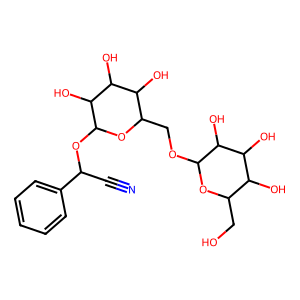

In [76]:
# Draw the example molecule
from rdkit.Chem import Draw

Draw.MolToImage(mol)

Read the element of atom 0.

In [7]:
# Inspect one atom
mol.GetAtomWithIdx(0).GetSymbol()

'N'

Read the type of bond 0.

In [8]:
# Inspect one bond
mol.GetBondWithIdx(0).GetBondType()

rdkit.Chem.rdchem.BondType.TRIPLE

Convert all ESOL SMILES strings to molecular graphs.

In [71]:
# Read the ESOL structures
esol_mols = [Chem.MolFromSmiles(s) for s in esol_smiles]
print(len(esol_mols))

1106


### Step 3. Calculate Descriptors

Use column order `[MW, HBD, HBA, TPSA, MolLogP]` for every molecule.

Calculate average molar mass in g/mol.

In [77]:
# Calculate MW
from rdkit.Chem import Descriptors

round(Descriptors.MolWt(mol), 3)

457.432

Count hydrogen-bond donors.

In [78]:
# Calculate HBD
from rdkit.Chem import Lipinski

Lipinski.NumHDonors(mol)

7

Count hydrogen-bond acceptors.

In [79]:
# Calculate HBA
Lipinski.NumHAcceptors(mol)

12

Calculate topological polar surface area in square angstroms.

In [80]:
# Calculate TPSA
from rdkit.Chem import rdMolDescriptors

rdMolDescriptors.CalcTPSA(mol)

202.32

Estimate the octanol/water logP.

In [81]:
# Calculate MolLogP
from rdkit.Chem import Crippen

round(Crippen.MolLogP(mol), 3)

-3.108

Combine the five descriptors into one vector.

In [15]:
# Define the descriptor calculation
descriptor_names = ['MW', 'HBD', 'HBA', 'TPSA', 'MolLogP']

def descriptor_row(molecule):
    return np.array([
        Descriptors.MolWt(molecule),
        Lipinski.NumHDonors(molecule),
        Lipinski.NumHAcceptors(molecule),
        rdMolDescriptors.CalcTPSA(molecule),
        Crippen.MolLogP(molecule),
    ], dtype=float)

Calculate the example molecule's descriptor vector.

In [82]:
# Apply the function to one molecule
descriptor_row(mol)

array([457.432,   7.   ,  12.   , 202.32 ,  -3.108])

Build one feature row per ESOL molecule.

In [83]:
# Construct the ESOL feature matrix
X_esol = np.vstack([descriptor_row(m) for m in esol_mols])

print('X shape:', X_esol.shape)
print('y shape:', y_esol.shape)
pd.DataFrame(X_esol[:4], columns=descriptor_names)

X shape: (1106, 5)
y shape: (1106,)


,MW,HBD,HBA,TPSA,MolLogP
0,457.432,7.0,12.0,202.32,-3.10802
1,201.225,1.0,2.0,42.24,2.84032
2,152.237,0.0,1.0,17.07,2.87800
3,278.354,0.0,0.0,0.00,6.29940


### Step 4. Split Training and Test Data

Keep 80% for training and 20% for testing.

In [84]:
# Split the ESOL rows
from sklearn.model_selection import train_test_split

esol_train_ids, esol_test_ids = train_test_split(
    np.arange(len(y_esol)), test_size=0.20, random_state=SEED,
)
Xr_train, Xr_test = X_esol[esol_train_ids], X_esol[esol_test_ids]
yr_train, yr_test = y_esol[esol_train_ids], y_esol[esol_test_ids]
print('Training molecules:', len(yr_train))
print('Test molecules:', len(yr_test))

Training molecules: 884
Test molecules: 222


### Step 5. Calculate a Baseline

Create five folds and a baseline that predicts the training mean.

In [19]:
# Define regression cross-validation and the baseline
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor

reg_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_baseline = DummyRegressor(strategy='mean')

Calculate baseline RMSE in each fold. Negate sklearn's error scores to recover RMSE.

In [20]:
# Evaluate the mean-prediction baseline
from sklearn.model_selection import cross_val_score

reg_baseline_scores = cross_val_score(
    reg_baseline, Xr_train, yr_train,
    cv=reg_cv, scoring='neg_root_mean_squared_error',
)
reg_baseline_rmse = -reg_baseline_scores
print('Fold RMSE:', reg_baseline_rmse)
print(f'Mean CV RMSE: {reg_baseline_rmse.mean():.3f}')

Fold RMSE: [2.084 2.259 2.089 1.934 2.125]
Mean CV RMSE: 2.098


### Step 6. Select Model Settings

Standardize descriptors inside the pipeline. Each training fold learns its own scaling.

In [21]:
# Define the scaled regression pipeline and candidate settings
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

reg_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('forest', RandomForestRegressor(n_estimators=200, random_state=SEED)),
])
reg_grid = {
    'forest__max_depth': [6, None],
    'forest__min_samples_leaf': [1, 4],
}

Cross-validate the whole pipeline, including the scaler.

In [22]:
# Search settings with scaling fitted inside each training fold
from sklearn.model_selection import GridSearchCV

reg_search = GridSearchCV(
    reg_pipeline, reg_grid, cv=reg_cv,
    scoring='neg_root_mean_squared_error',
)
reg_search.fit(Xr_train, yr_train);

Display validation RMSE for each setting.

In [23]:
# Read the cross-validation results
reg_cv_rmse = -reg_search.cv_results_['mean_test_score']
reg_cv_sd = reg_search.cv_results_['std_test_score']
for settings, mean, sd in zip(reg_search.cv_results_['params'], reg_cv_rmse, reg_cv_sd):
    print(f'{settings}  RMSE {mean:.3f}  SD {sd:.3f}')

{'forest__max_depth': 6, 'forest__min_samples_leaf': 1}  RMSE 0.766  SD 0.063
{'forest__max_depth': 6, 'forest__min_samples_leaf': 4}  RMSE 0.758  SD 0.064
{'forest__max_depth': None, 'forest__min_samples_leaf': 1}  RMSE 0.743  SD 0.064
{'forest__max_depth': None, 'forest__min_samples_leaf': 4}  RMSE 0.741  SD 0.064


Keep the fitted pipeline with the lowest mean validation RMSE.

In [24]:
# Select the best regression model
print('Selected settings:', reg_search.best_params_)
print(f'Selected CV RMSE: {-reg_search.best_score_:.3f}')
reg_model = reg_search.best_estimator_

Selected settings: {'forest__max_depth': None, 'forest__min_samples_leaf': 4}
Selected CV RMSE: 0.741


### Step 7. Evaluate the Test Set

The selected pipeline refits on all training rows and transforms the test descriptors.

In [25]:
# Calculate the regression test errors
from sklearn.metrics import mean_squared_error, mean_absolute_error

reg_pred = reg_model.predict(Xr_test)
print(f'Test RMSE: {np.sqrt(mean_squared_error(yr_test, reg_pred)):.3f}')
print(f'Test MAE:  {mean_absolute_error(yr_test, reg_pred):.3f}')

Test RMSE: 0.723
Test MAE:  0.503


Compare measured and predicted logS, and inspect residuals.

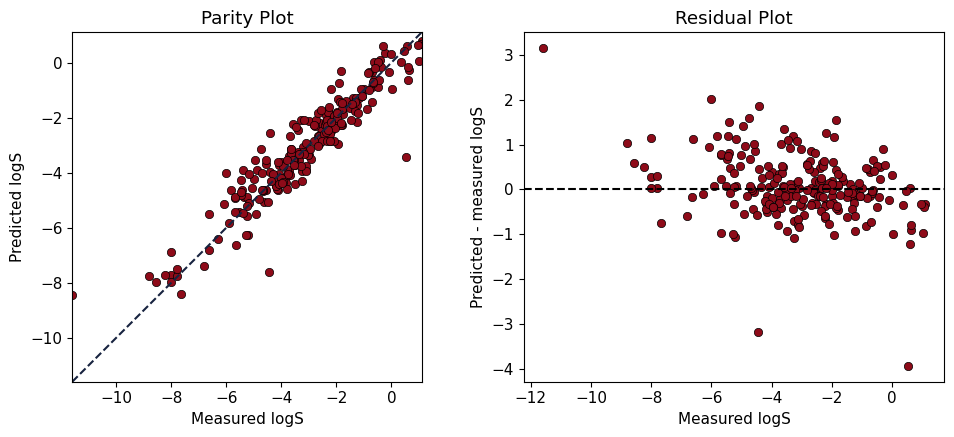

In [26]:
# Plot the regression test results
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
limits = [min(yr_test.min(), reg_pred.min()), max(yr_test.max(), reg_pred.max())]
axes[0].scatter(yr_test, reg_pred, color=RED, edgecolor='black', linewidth=0.5, s=36)
axes[0].plot(limits, limits, color=NAVY, linestyle='--')
axes[0].set(xlabel='Measured logS', ylabel='Predicted logS',
            xlim=limits, ylim=limits, title='Parity Plot')
axes[0].set_aspect('equal', adjustable='box')
reg_residual = reg_pred - yr_test
axes[1].scatter(yr_test, reg_residual, color=RED, edgecolor='black', linewidth=0.5, s=36)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Measured logS', ylabel='Predicted - measured logS',
            title='Residual Plot')
fig.tight_layout()
plt.show()

### Step 8. Predict a New Molecule

Read and draw a new molecule.

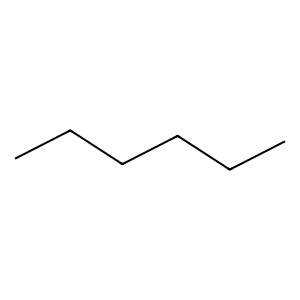

In [89]:
# Create a solubility query
# solubility_query = Chem.MolFromSmiles('CCCOc1ccc(NC(=O)CC)cc1')
solubility_query = Chem.MolFromSmiles('CCCCCC')
# solubility_query = Chem.MolFromSmiles('CCO')
Draw.MolToImage(solubility_query)

Pass the query descriptors to the fitted pipeline to predict solubility.

In [90]:
# Predict the query solubility
query_descriptors = descriptor_row(solubility_query).reshape(1, -1)
query_logS = reg_model.predict(query_descriptors)[0]
print(f'Predicted logS: {query_logS:.3f}')
print(f'Predicted S (mol/L): {10.0 ** query_logS:.3g}')

Predicted logS: -3.738
Predicted S (mol/L): 0.000183


## BBBP Classification

### Step 1. Read the Data

The target `p_np` is 0 for non-penetrating and 1 for penetrating.

Load BBBP and view its first four rows.

In [29]:
# Read the BBBP CSV file
bbbp = pd.read_csv('data/molecular_prediction/bbbp.csv')
bbbp.head(4)

,name,smiles,p_np
0,Propanolol,CC(C)NCC(O)COc1cccc2ccccc12.[Cl],1
1,cloxacillin,Cc1onc(-c2ccccc2Cl)c1C(=O)N[C@@H]1C(=O)N2[C@@H...,1
2,cefoperazone,CCN1CCN(C(=O)N[C@@H](C(=O)N[C@@H]2C(=O)N3C(C(=...,1
3,rolitetracycline,CN(C)[C@@H]1C(=O)/C(=C(/O)NCN2CCCC2)C(=O)[C@@]...,1


Extract SMILES strings and binary labels.

In [30]:
# Convert the BBBP columns to NumPy arrays
bbbp_smiles = bbbp['smiles'].to_numpy(dtype=str)
y_bbbp = bbbp['p_np'].to_numpy(dtype=int)
print('Molecules:', len(y_bbbp))
print('Labels:', np.unique(y_bbbp))

Molecules: 1915
Labels: [0 1]


### Step 2. Read the Structures

Convert all BBBP SMILES strings to molecular graphs.

In [58]:
# Read the BBBP structures
bbbp_mols = [Chem.MolFromSmiles(s) for s in bbbp_smiles]

[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:58] WARNING: not removing hydrogen atom without neighbors
[10:14:59] WARNING: not r

Count molecules in each penetration class.

In [32]:
# Count the class labels
class_counts = np.bincount(y_bbbp, minlength=2)
print('Non-penetrating (0):', class_counts[0])
print('Penetrating (1):', class_counts[1])
print(f'Fraction labeled 1: {y_bbbp.mean():.3f}')

Non-penetrating (0): 462
Penetrating (1): 1453
Fraction labeled 1: 0.759


Compare the number of molecules in each class.

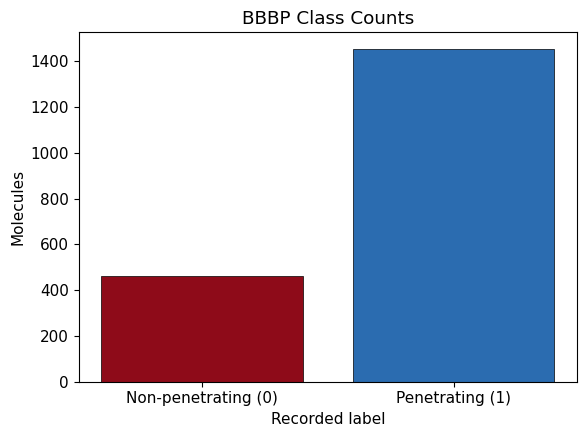

In [33]:
# Plot the class counts
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(['Non-penetrating (0)', 'Penetrating (1)'], class_counts,
       color=[RED, BLUE], edgecolor='black', linewidth=0.5)
ax.set(xlabel='Recorded label', ylabel='Molecules', title='BBBP Class Counts')
fig.tight_layout()
plt.show()

### Step 3. Calculate Morgan Fingerprints

Configure 2048-bit Morgan fingerprints with radius 2 and chirality enabled.

In [34]:
# Define the Morgan fingerprint generator
from rdkit.Chem import rdFingerprintGenerator

morgan = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048, includeChirality=True,
)

Display one BBBP molecule.

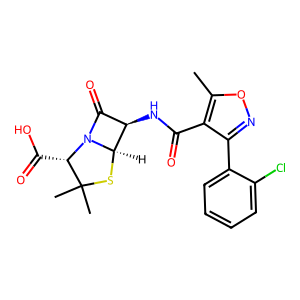

In [35]:
# Draw the BBBP example
bbbp_mol = bbbp_mols[1]
Draw.MolToImage(bbbp_mol)

Calculate one binary fingerprint.

In [36]:
# Generate the example fingerprint
one_fingerprint = morgan.GetFingerprintAsNumPy(bbbp_mol)
print('Positions:', one_fingerprint.size)
print('Active positions:', np.count_nonzero(one_fingerprint))

Positions: 2048
Active positions: 57


Build one fingerprint row per BBBP molecule.

In [37]:
# Construct the BBBP feature matrix
X_bbbp = np.vstack([morgan.GetFingerprintAsNumPy(m) for m in bbbp_mols])
print('X shape:', X_bbbp.shape)
print('y shape:', y_bbbp.shape)
print('Feature values:', np.unique(X_bbbp))

X shape: (1915, 2048)
y shape: (1915,)
Feature values: [0 1]


### Step 4. Split Training and Test Data

Use a stratified 80/20 training-test split.

In [38]:
# Split the BBBP rows by label
bbbp_train_ids, bbbp_test_ids = train_test_split(
    np.arange(len(y_bbbp)), test_size=0.20, random_state=SEED, stratify=y_bbbp,
)
Xc_train, Xc_test = X_bbbp[bbbp_train_ids], X_bbbp[bbbp_test_ids]
yc_train, yc_test = y_bbbp[bbbp_train_ids], y_bbbp[bbbp_test_ids]
print('Training molecules:', len(yc_train))
print('Test molecules:', len(yc_test))
print('Training class counts:', np.bincount(yc_train, minlength=2))
print('Test class counts:', np.bincount(yc_test, minlength=2))

Training molecules: 1532
Test molecules: 383
Training class counts: [ 370 1162]
Test class counts: [ 92 291]


### Step 5. Calculate a Baseline

Define five stratified folds and a constant-score baseline.

In [39]:
# Define classification cross-validation and the baseline
from sklearn.model_selection import StratifiedKFold
from sklearn.dummy import DummyClassifier

class_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
class_baseline = DummyClassifier(strategy='prior')

Calculate baseline ROC AUC in each fold. Constant scores give 0.5.

In [40]:
# Evaluate the classification baseline
class_baseline_scores = cross_val_score(
    class_baseline, Xc_train, yc_train, cv=class_cv, scoring='roc_auc',
)
print('Fold ROC AUC:', class_baseline_scores)
print(f'Mean CV ROC AUC: {class_baseline_scores.mean():.3f}')

Fold ROC AUC: [0.5 0.5 0.5 0.5 0.5]
Mean CV ROC AUC: 0.500


### Step 6. Fit the Pipeline Within Five-Fold Cross-Validation

Select the first of the five training folds.

In [41]:
# Get training and validation row indices
folds = list(class_cv.split(Xc_train, yc_train))
fit_rows, validation_rows = folds[0]

Build a pipeline that standardizes fingerprints before PCA and classification.
PCA retains 90% of the scaled training variance.

In [42]:
# Define the scaled PCA classification pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

class_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.90, svd_solver='full')),
    ('logistic', LogisticRegression(
        C=1.0, class_weight='balanced', max_iter=3000, random_state=SEED,
    )),
])

Fit a fresh pipeline on the first fold's training rows.

In [43]:
# Fit scaling and PCA within one training fold
from sklearn.base import clone

fold_model = clone(class_pipeline)
fold_model.fit(Xc_train[fit_rows], yc_train[fit_rows]);

Inspect how the fitted scaler and PCA transform the two subsets.

In [44]:
# Apply the learned preprocessing to training and validation rows
fold_scaler = fold_model.named_steps['scale']
fold_pca = fold_model.named_steps['pca']
scaled_fit = fold_scaler.transform(Xc_train[fit_rows])
scaled_validation = fold_scaler.transform(Xc_train[validation_rows])
Z_fit = fold_pca.transform(scaled_fit)
Z_validation = fold_pca.transform(scaled_validation)
print('Training PC shape:', Z_fit.shape)
print('Validation PC shape:', Z_validation.shape)

Training PC shape: (1225, 601)
Validation PC shape: (307, 601)


Predict validation labels from raw fingerprints through the fitted pipeline.

In [45]:
# Score the first validation fold using the complete pipeline
from sklearn.metrics import roc_auc_score

fold_probability = fold_model.predict_proba(Xc_train[validation_rows])[:, 1]
roc_auc_score(yc_train[validation_rows], fold_probability)

0.9032594826586243

Fit a fresh pipeline for every fold and C value. Each fit relearns scaling and PCA.

In [46]:
# Cross-validate the whole pipeline across all five folds
C_values = np.array([0.1, 1.0, 10.0])
cv_auc = np.zeros((5, len(C_values)))
pc_counts = np.zeros(5, dtype=int)

for fold, (fit_rows, validation_rows) in enumerate(folds):
    for j, C in enumerate(C_values):
        fold_model = clone(class_pipeline)
        fold_model.set_params(logistic__C=C)
        fold_model.fit(Xc_train[fit_rows], yc_train[fit_rows])
        probability = fold_model.predict_proba(Xc_train[validation_rows])[:, 1]
        cv_auc[fold, j] = roc_auc_score(yc_train[validation_rows], probability)
    pc_counts[fold] = fold_model.named_steps['pca'].n_components_

Display component counts and validation AUCs for all five folds.

In [47]:
# Inspect the fold results
print('PCs in each fold:', pc_counts)
pd.DataFrame(
    cv_auc, index=[f'Fold {i}' for i in range(1, 6)],
    columns=[f'C={C:g}' for C in C_values],
)

PCs in each fold: [601 590 598 596 599]


,C=0.1,C=1,C=10
Fold 1,0.909871,0.903259,0.898794
Fold 2,0.861849,0.859007,0.859471
Fold 3,0.907153,0.904473,0.902610
Fold 4,0.870107,0.859739,0.844420
Fold 5,0.886883,0.866554,0.858982


Choose the C value with the highest mean validation AUC.

In [48]:
# Select the classifier regularization
mean_auc = cv_auc.mean(axis=0)
best_C = C_values[np.argmax(mean_auc)]
print('Mean CV ROC AUC:', mean_auc)
print('Selected C:', best_C)

Mean CV ROC AUC: [0.887 0.879 0.873]
Selected C: 0.1


Refit the selected pipeline on all training rows. It learns the final scaler and PCA.

In [49]:
# Refit the selected pipeline on the full training set
class_model = clone(class_pipeline)
class_model.set_params(logistic__C=best_C)
class_model.fit(Xc_train, yc_train)
print('Final PCA components:', class_model.named_steps['pca'].n_components_)

Final PCA components: 676


Project training fingerprints using the pipeline's fitted scaler and PCA.

In [50]:
# Project training fingerprints with the fitted preprocessing
training_scaled = class_model.named_steps['scale'].transform(Xc_train)
training_pcs = class_model.named_steps['pca'].transform(training_scaled)
pca_variance = 100 * class_model.named_steps['pca'].explained_variance_ratio_

Plot PC1 and PC2 by label. Percentages refer to scaled fingerprint variance. The classifier uses all retained components.

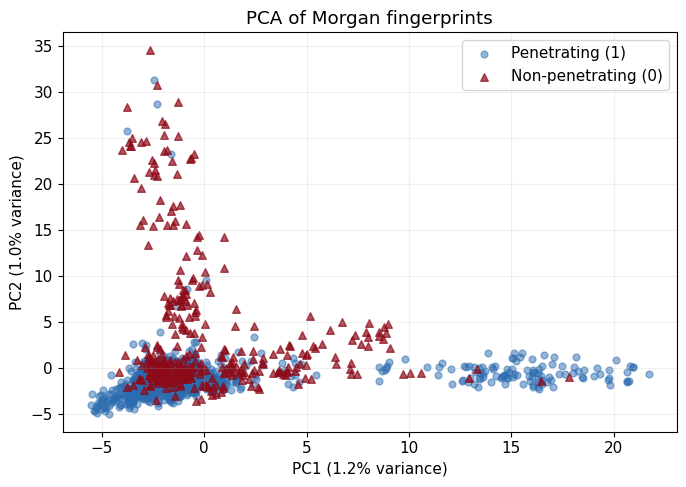

In [51]:
# Plot the first two principal components by BBBP label
penetrating = yc_train == 1
non_penetrating = yc_train == 0

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(training_pcs[penetrating, 0], training_pcs[penetrating, 1],
           color=BLUE, marker='o', s=24, alpha=0.5, label='Penetrating (1)')
ax.scatter(training_pcs[non_penetrating, 0], training_pcs[non_penetrating, 1],
           color=RED, marker='^', s=30, alpha=0.7, label='Non-penetrating (0)')
ax.set_xlabel(f'PC1 ({pca_variance[0]:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca_variance[1]:.1f}% variance)')
ax.set_title('PCA of Morgan fingerprints')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

### Step 7. Evaluate the Test Set

Pass raw test fingerprints to the fitted pipeline for preprocessing and prediction.

In [52]:
# Evaluate test predictions from the complete pipeline
from sklearn.metrics import average_precision_score, balanced_accuracy_score

class_probability = class_model.predict_proba(Xc_test)[:, 1]
class_pred = class_model.predict(Xc_test)
print(f'Test ROC AUC: {roc_auc_score(yc_test, class_probability):.3f}')
print(f'Test AP: {average_precision_score(yc_test, class_probability):.3f}')
print(f'Balanced accuracy: {balanced_accuracy_score(yc_test, class_pred):.3f}')

Test ROC AUC: 0.903
Test AP: 0.959
Balanced accuracy: 0.830


Compare predicted and recorded labels.

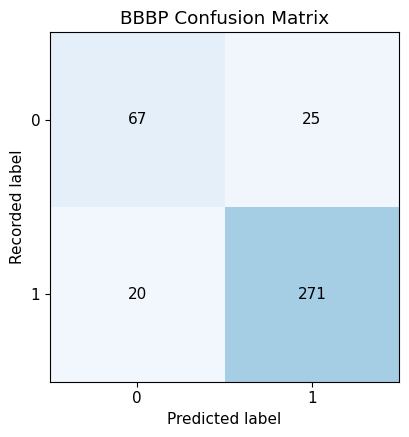

In [53]:
# Plot the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm_display = ConfusionMatrixDisplay.from_predictions(
    yc_test, class_pred, labels=[0, 1], display_labels=['0', '1'],
    cmap='Blues', colorbar=False, ax=ax,
    im_kw={'vmin': 0, 'vmax': 2 * len(yc_test)},
)
for text in cm_display.text_.ravel():
    text.set_color('black')
ax.set(xlabel='Predicted label', ylabel='Recorded label',
       title='BBBP Confusion Matrix')
fig.tight_layout()
plt.show()

Plot ROC and precision-recall curves from the test scores.

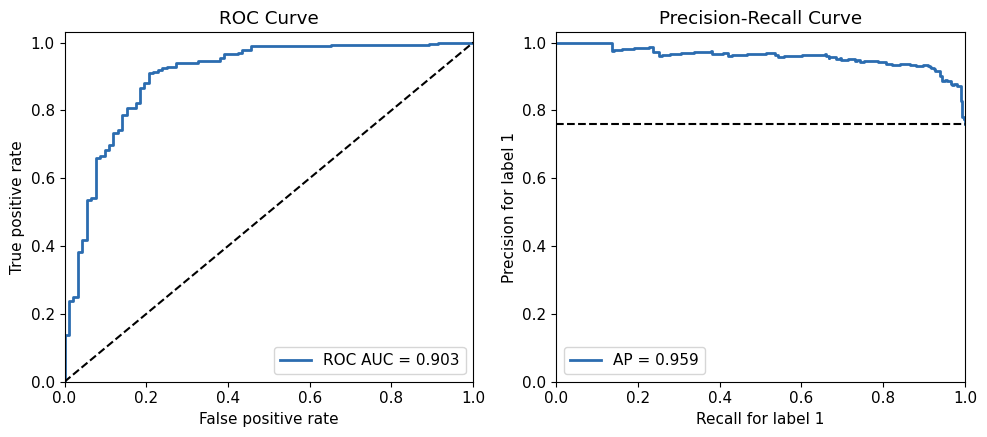

In [54]:
# Plot the classification curves
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, roc_thresholds = roc_curve(yc_test, class_probability)
precision, recall, pr_thresholds = precision_recall_curve(yc_test, class_probability)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].plot(fpr, tpr, color=BLUE, linewidth=2,
             label=f'ROC AUC = {roc_auc_score(yc_test, class_probability):.3f}')
axes[0].plot([0, 1], [0, 1], color='black', linestyle='--')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate',
            xlim=(0, 1), ylim=(0, 1.03), title='ROC Curve')
axes[0].legend(loc='lower right')
axes[1].step(recall, precision, where='post', color=BLUE, linewidth=2,
             label=f'AP = {average_precision_score(yc_test, class_probability):.3f}')
axes[1].axhline(yc_test.mean(), color='black', linestyle='--')
axes[1].set(xlabel='Recall for label 1', ylabel='Precision for label 1',
            xlim=(0, 1), ylim=(0, 1.03), title='Precision-Recall Curve')
axes[1].legend(loc='lower left')
fig.tight_layout()
plt.show()

### Step 8. Predict a New Molecule

Read and draw a new molecule.

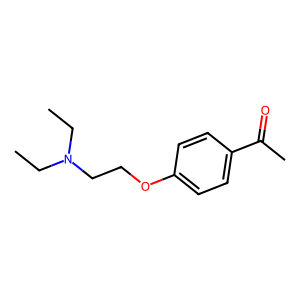

In [55]:
# Create a penetration query
penetration_query = Chem.MolFromSmiles('CCN(CC)CCOc1ccc(C(C)=O)cc1')
Draw.MolToImage(penetration_query)

Calculate the query fingerprint for the fitted pipeline.

In [56]:
# Calculate the query fingerprint
query_bits = morgan.GetFingerprintAsNumPy(penetration_query).reshape(1, -1)

Use the fitted pipeline to scale the query and predict its penetration label.

In [57]:
# Predict query penetration with the complete pipeline
query_probability = class_model.predict_proba(query_bits)[0, 1]
query_label = class_model.predict(query_bits)[0]
print(f'Model probability for label 1: {query_probability:.3f}')
print('Predicted label:', query_label)

Model probability for label 1: 0.991
Predicted label: 1
